In this notebook, I read in the GEO data GSE150059 and perform some basic checks on it.
- The data is GEO series matrix is parsed through the "read_series_matrix" function from src/geo.py

In [1]:
import pandas as pd
import gzip, io
import sys
sys.path.append("..")

#Reading local series matrix file
path = "/data/GSE150059_series_matrix.txt.gz"


Setup: This snippet reads in the data

In [2]:
from src.geo import read_series_matrix

expr, meta = read_series_matrix("../data/GSE150059_series_matrix.txt.gz")

1) Fixing the metadata to create proper columns for analysis

In [3]:
chars = meta.filter(like = "characteristics")
labels = pd.DataFrame(index = meta.index)

for i in range(chars.shape[1]):
    col = chars.iloc[:, i].str.split(": ", n = 1)   #"diagnosis: TCMR" -> ["diagnosis", "TCMR"] 
    name = col.str[0].mode()[0]             # most common key becomes column name
    labels[name] = col.str[1]

labels.nunique()  # number of distinct values per label

counts = labels["mmdx"].value_counts().rename_axis("MMDx diagnosis").to_frame("n")
counts["%"] = (counts["n"] / counts["n"].sum() * 100).round(1)
counts

,n,%
MMDx diagnosis,,
NR Normal,462,35.0
NR Minor,359,27.2
ABMR,179,13.6
pABMR,161,12.2
TCMR,76,5.8
pTCMR,38,2.9
NR Early-injury,32,2.4
Mixed,13,1.0


2) Checking expression values

In [4]:
print(expr.shape) 
print(expr.isna().sum().sum())
print(expr.min().min(), expr.max().max)
expr.iloc[:, :5].describe()

(49495, 1320)
0
2.114227263 <bound method Series.max of GSM4521569    14.842842
GSM4521570    14.784500
GSM4521571    14.799748
GSM4521572    14.856877
GSM4521573    14.865249
                ...    
GSM4522884    14.790189
GSM4522885    14.792531
GSM4522886    14.646495
GSM4522887    14.775084
GSM4522888    14.781129
Length: 1320, dtype: float64>


,GSM4521569,GSM4521570,GSM4521571,GSM4521572,GSM4521573
count,49495.000000,49495.000000,49495.000000,49495.000000,49495.000000
mean,6.339684,6.331669,6.343666,6.332862,6.339182
std,2.134661,2.125869,2.104130,2.064406,2.181373
min,2.421985,2.394776,2.346554,2.323043,2.268551
25%,4.669624,4.652784,4.696382,4.750150,4.585843
50%,6.195449,6.209434,6.221013,6.218382,6.211410
75%,7.747404,7.749783,7.735657,7.694040,7.835184
max,14.842842,14.784500,14.799748,14.856877,14.865249


This microarray (Affymetrix) data seem to be already log2 Normalized.

3) Let's filter missing values or any affymetrix control probes

In [5]:
expr = expr.dropna()
expr = expr[~expr.index.str.startswith("AFFX")]  #Removing affymetrix control probes
top = expr.var(axis=1).sort_values(ascending=False).index[:5000]
expr_top = expr.loc[top]
print(expr_top.shape)
print(expr_top.dtypes.value_counts())

(5000, 1320)
float64    1320
Name: count, dtype: int64


Filtering step is complete. I kept top 5000 variables to run a PCA

4) PCA

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X = expr_top.T.loc[labels.index]    #samples x probes and then match the order with label dataframe
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=10)
scores = pca.fit_transform(X_scaled)

pcs = pd.DataFrame(scores[:, :2], index=X.index, columns=["PC1", "PC2"]).join(labels)
pca.explained_variance_ratio_.round(3)                   # variance per PC


array([0.295, 0.107, 0.068, 0.05 , 0.038, 0.033, 0.024, 0.017, 0.016,
       0.015])

PCA was run and saved in the `scores` variable. Then, I created a new data frame, adding the index as the X matrix, picking up first 2 scores columns (PC1 and PC2), then joining it with labels that include the diagnosis column, mmdx.

5) Now Plotting it

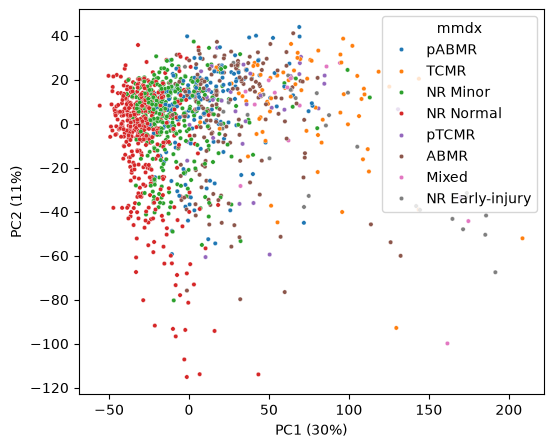

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 5))                  #Creating an empty plot of 6 into 5 inches
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="mmdx", s=10, ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
fig.savefig("../results/pca_by_label.png", dpi=150, bbox_inches="tight")

In [14]:
fig.savefig("../figures/pca_by_label.png", dpi=150, bbox_inches="tight")